In [1]:
# %pip install sidetable
# %conda install -c conda-forge --yes scienceplots

In [1]:
import os
from configparser import ConfigParser
from matplotlib import pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd
import scienceplots
import seaborn as sns
import sidetable

In [2]:
plt.style.use(['science','no-latex'])

In [3]:
os.getcwd()

'/Users/janik/source/urban-mobility-simulation/resources/scripts/simulation_analysis'

In [4]:
os.chdir("../../../")
os.getcwd()

'/Users/janik/source/urban-mobility-simulation'

In [5]:
from simulation.helper.time import SimulationTimeConverter

In [6]:
# Read args
parser = ConfigParser()
parser.read("resources/configurations/shared-charging.ini")

['resources/configurations/shared-charging.ini']

In [7]:
runs = pd.read_csv("data/output/run_configs.csv")
runs = runs.sort_values(by="timestamp")
runs.tail(3)

,timestamp,experiment,duration_sim_min,duration_real_sec,n_vehicles,n_charging_stations,capacity_per_station,kW,seed,service_level_fleet_0,service_level_fleet_1,avg_util_infra_0,avg_util_infra_1,notes
22,20240816_16:22:24,WITS_benchmark_uncoordinated_separated.py,2880,315.800542,500,9,2.0,22.0,43,0.193281,0.187028,0.992088,0.992088,random_SOC_init
23,20240816_16:22:27,WITS_benchmark_uncoordinated.py,2880,323.269419,500,9,4.0,22.0,43,0.195600,0.190348,0.969058,NaN,random_SOC_init
24,20240816_16:22:30,WITS_coordinated_shared_charging.py,2880,602.268797,500,9,4.0,22.0,43,0.495537,0.470278,0.896559,NaN,"random_SOC_init, overbidding: (True, 0.3), auc..."


In [8]:
runs[['timestamp', 'experiment', 'service_level_fleet_0', 'service_level_fleet_1', 'avg_util_infra_0', 'avg_util_infra_1', 'notes']].tail(8)

,timestamp,experiment,service_level_fleet_0,service_level_fleet_1,avg_util_infra_0,avg_util_infra_1,notes
17,20240815_23:05:36,WITS_coordinated_shared_charging.py,0.571044,0.579075,0.588775,NaN,"random_SOC_init, overbidding: (True, 0.3)"
18,20240816_14:54:51,WITS_coordinated_shared_charging.py,0.602210,0.606110,0.255075,NaN,"random_SOC_init, overbidding: (True, 0.3), auc..."
19,20240816_14:55:02,WITS_benchmark_uncoordinated.py,0.593496,0.606771,0.503213,NaN,random_SOC_init
20,20240816_14:55:14,WITS_benchmark_uncoordinated_separated.py,0.604750,0.595455,0.502817,0.502817,random_SOC_init
21,20240816_16:12:57,WITS_coordinated_shared_charging.py,0.513593,0.459912,0.880861,NaN,"random_SOC_init, overbidding: (True, 0.3), auc..."
22,20240816_16:22:24,WITS_benchmark_uncoordinated_separated.py,0.193281,0.187028,0.992088,0.992088,random_SOC_init
23,20240816_16:22:27,WITS_benchmark_uncoordinated.py,0.195600,0.190348,0.969058,NaN,random_SOC_init
24,20240816_16:22:30,WITS_coordinated_shared_charging.py,0.495537,0.470278,0.896559,NaN,"random_SOC_init, overbidding: (True, 0.3), auc..."


In [9]:
RUN_UNCOORDINATED = "20240816_16:22:27"
RUN_SEPERATE = "20240816_16:22:24"
RUN_COORDINATED = "20240816_16:22:30"

In [10]:
SIM_DAYS = parser.getint("EXPERIMENT_MANAGEMENT", "END_TIME") // 1440 + 1

## Auction

In [12]:
auction_tracking = pd.read_csv(f"data/output/tracking/{RUN_COORDINATED}_auction.csv")

In [13]:
auction_tracking

,time,participant_id,location,_bids,_result
0,5,0,872664521ffffff,"[(1, 0.4037462036511208), (1, 0.78004370862983...","(3, 0.7794442235328854)"
1,5,0,872664c10ffffff,"[(1, 0.6573834888648189), (1, 0.65823213667244...","(2, 0.6582321366724418)"
2,5,0,872664c1affffff,"[(1, 0.433426885056306), (1, 0.608224604734404...","(2, 0.658519499359525)"
3,5,0,872664c1effffff,"[(1, 0.5244484965193256), (1, 0.64563147527954...","(1, 0.7798692028348756)"
4,5,0,872664ca9ffffff,"[(1, 0.4229531438748934), (1, 0.65746391844264...","(2, 0.6574639184426451)"
...,...,...,...,...,...
1118,2830,1,872664521ffffff,"[(1, 0.7800709874886212)]","(0, 0.0)"
1119,2840,0,872664521ffffff,"[(1, 0.7800709874886212)]","(0, 0.0)"
1120,2840,1,872664521ffffff,"[(1, 0.7800709874886212)]","(1, 0.7800709874886212)"
1121,2845,0,872664521ffffff,"[(1, 0.7800709874886212)]","(1, 0.7800709874886212)"


In [14]:
# rename time axis
auction_tracking['timestamp'] = pd.to_datetime(auction_tracking['time'].apply(SimulationTimeConverter.as_datetime))

In [15]:
auction_tracking['_result.clearing_price'] = auction_tracking['_result'].apply(lambda x: eval(x)[1])
auction_tracking['_result.capacity'] = auction_tracking['_result'].apply(lambda x: eval(x)[0])

auction_tracking['_bids.total_capacity'] = auction_tracking['_bids'].apply(lambda x: sum([b[0] for b in eval(x)]))
auction_tracking['_bids.mean_bid'] = auction_tracking['_bids'].apply(lambda x: np.mean([b[1] for b in eval(x)]))

In [16]:
auction_tracking[(auction_tracking['_bids.total_capacity'] - auction_tracking['_result.capacity']) <0]

,time,participant_id,location,_bids,_result,timestamp,_result.clearing_price,_result.capacity,_bids.total_capacity,_bids.mean_bid


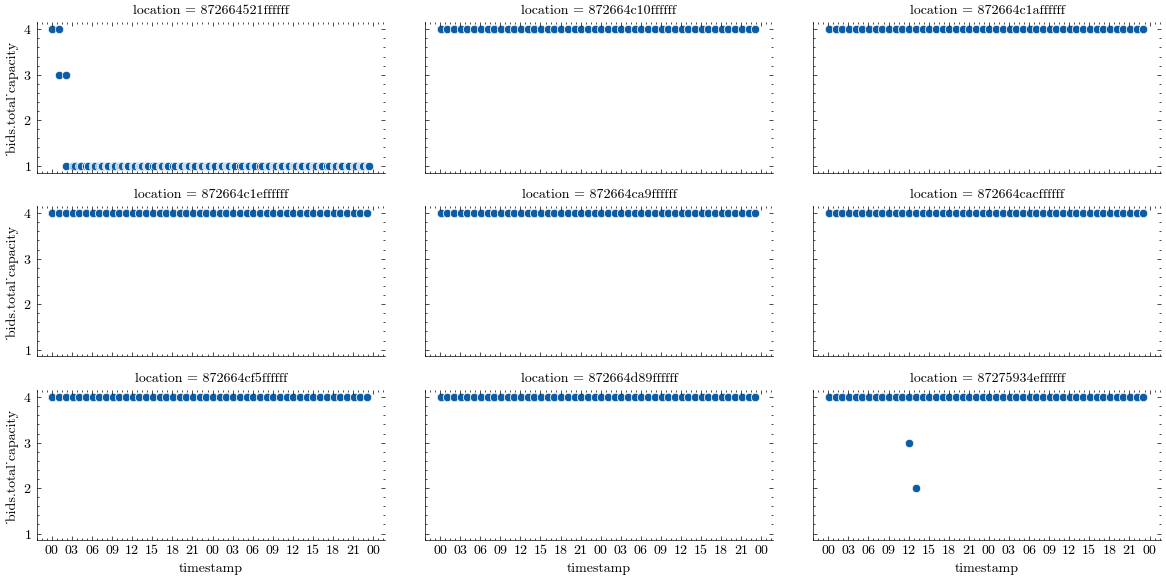

In [17]:
auction_tracking.sort_values(by=['time', 'location'], inplace=True)
g = sns.relplot(data=auction_tracking, x="timestamp", y="_bids.total_capacity", col="location", col_wrap=3, kind="scatter", height=2, aspect = 2)

axes = g.axes.flat

for a in axes:
    a.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=24))
    a.xaxis.set_major_formatter(mdates.DateFormatter('%H'))

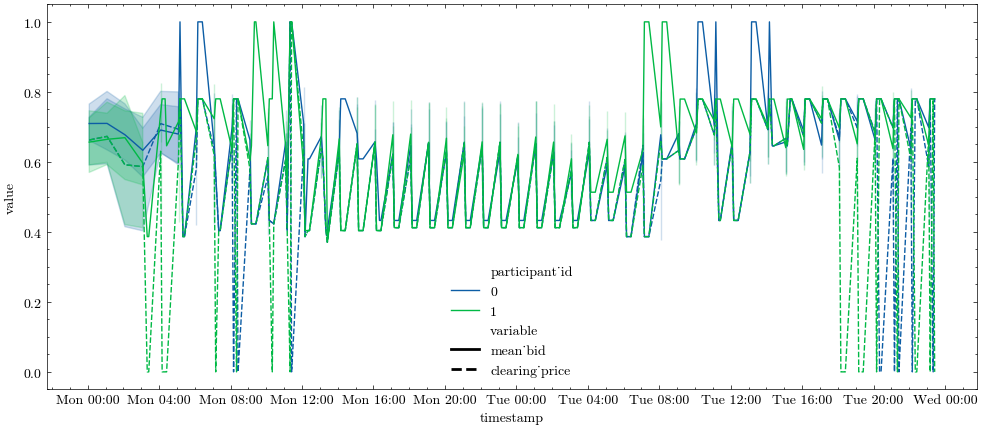

In [18]:
from matplotlib.lines import Line2D


fig, ax = plt.subplots(1,1, figsize=(12,5))

auction_tracking_long = auction_tracking.melt(id_vars=['timestamp', 'location', 'participant_id'], value_vars=['_result.clearing_price', '_bids.mean_bid'])
auction_tracking_long['variable'] = auction_tracking_long['variable'].astype('category')

sns.lineplot(data=auction_tracking_long, x="timestamp", y="value", hue="participant_id", style="variable", ax=ax)

handles, labels = ax.get_legend_handles_labels()
handles.append(Line2D([0], [0], color='black', lw=2, linestyle='solid'))
handles.append(Line2D([0], [0], color='black', lw=2, linestyle='dashed'))
labels.extend(['mean_bid', 'clearing_price'])

ax.legend(handles=handles, labels=labels)

ax.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=SIM_DAYS * 6))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%a %H:%M'))

In [19]:
auction_tracking_hourly = auction_tracking.groupby('participant_id').resample('6h', on='timestamp').agg({'_bids.mean_bid': 'mean', '_result.clearing_price': 'mean'}).reset_index()

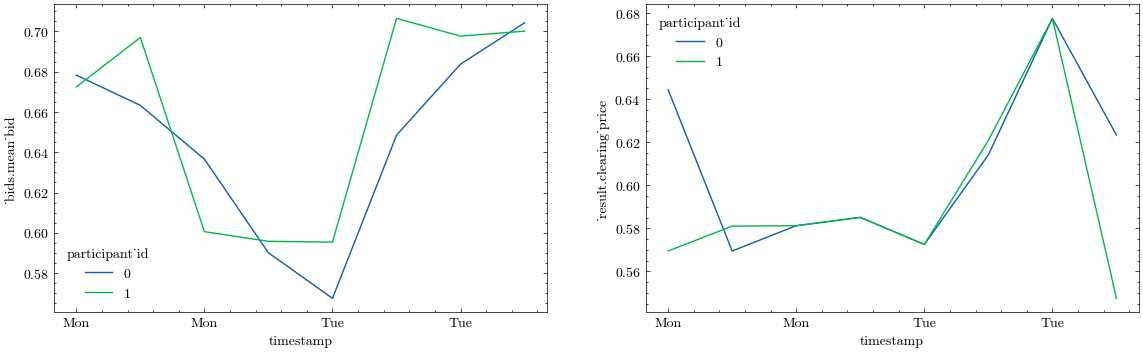

In [20]:
from matplotlib.lines import Line2D


fig, ax = plt.subplots(1,2, figsize=(14,4))

sns.lineplot(data=auction_tracking_hourly, x="timestamp", y="_bids.mean_bid", hue="participant_id", ax=ax[0])
sns.lineplot(data=auction_tracking_hourly, x="timestamp", y="_result.clearing_price", hue="participant_id", ax=ax[1])

for a in ax:
    a.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=SIM_DAYS * 2))
    a.xaxis.set_major_formatter(mdates.DateFormatter('%a'))

## Vehicles

In [11]:
vehicle_tracking_coordinated = pd.read_csv(f"data/output/tracking/{RUN_COORDINATED}_vehicles.csv")

In [12]:
RECHARGE_THRESHOLD = 25 # ATTENTION: This is an approximation, we use dynamic ones per hour # TODO: use dynamic from config

vehicle_tracking_coordinated['fleet_average_SOC'] = vehicle_tracking_coordinated['_current_state_of_charge'].apply(lambda x: np.mean(eval(x))) / parser.getfloat("AUTONOMOUS_CAR", "MAX_STATE_OF_CHARGE")
vehicle_tracking_coordinated['fleet_number_low_SOC'] = vehicle_tracking_coordinated['_current_state_of_charge'].apply(lambda x: np.count_nonzero(np.array(eval(x))< RECHARGE_THRESHOLD))

In [13]:
# rename time axis
vehicle_tracking_coordinated.rename(columns={'time': 'simtime'}, inplace=True)
vehicle_tracking_coordinated['time'] = pd.to_datetime(vehicle_tracking_coordinated['simtime'].apply(SimulationTimeConverter.as_datetime))

# vehicle_tracking_coordinated['timestamp'] = vehicle_tracking_coordinated['time'].dt.strftime("%H:%M")

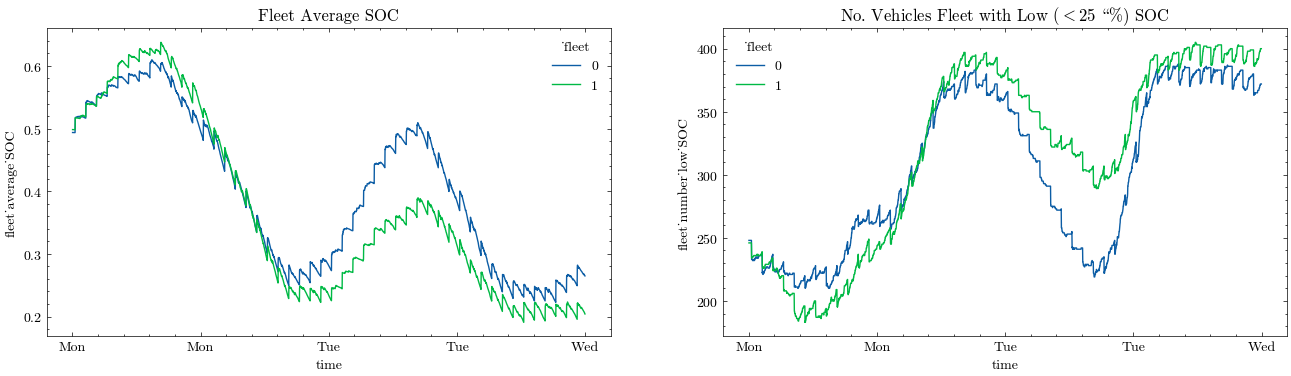

In [14]:
fig, ax = plt.subplots(nrows = 1, ncols = 2, figsize = (16, 4))

sns.lineplot(data=vehicle_tracking_coordinated, x='time', y='fleet_average_SOC', hue='_fleet', ax = ax[0])
sns.lineplot(data=vehicle_tracking_coordinated, x='time', y='fleet_number_low_SOC', hue='_fleet', ax = ax[1])

ax[0].set_title('Fleet Average SOC')
ax[1].set_title(f'No. Vehicles Fleet with Low ($< {RECHARGE_THRESHOLD}$ \%) SOC')

for a in ax:
    a.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=SIM_DAYS * 2))
    a.xaxis.set_major_formatter(mdates.DateFormatter('%a'))

plt.show()

### with temporal varying thresholds

In [15]:
RECHARGE_THRESHOLD = [float(x) for x in parser.get("RIDE_HAILING_OPERATOR", "RECHARGE_THRESHOLD").split(",")]

# vehicle_tracking_coordinated['fleet_average_SOC'] = vehicle_tracking_coordinated['_current_state_of_charge'].apply(lambda x: np.mean(eval(x))) / parser.getfloat("AUTONOMOUS_CAR", "MAX_STATE_OF_CHARGE")
vehicle_tracking_coordinated['hour'] = vehicle_tracking_coordinated['simtime'].apply(lambda x: SimulationTimeConverter.hours(int(x)))
vehicle_tracking_coordinated['fleet_number_low_SOC'] = vehicle_tracking_coordinated.apply(lambda x: np.count_nonzero(np.array(eval(x['_current_state_of_charge'])) < RECHARGE_THRESHOLD[x['hour']]), axis=1)

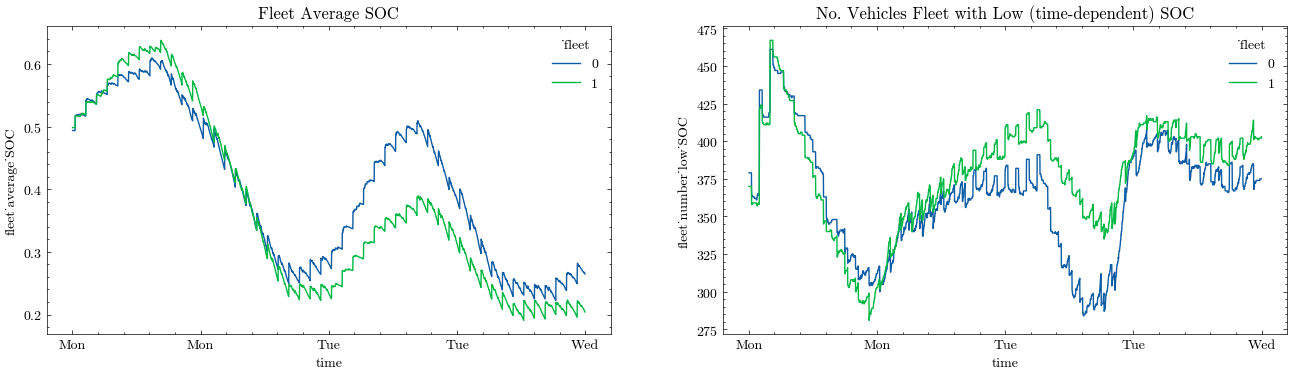

In [16]:
fig, ax = plt.subplots(nrows = 1, ncols = 2, figsize = (16, 4))

sns.lineplot(data=vehicle_tracking_coordinated, x='time', y='fleet_average_SOC', hue='_fleet', ax = ax[0])
sns.lineplot(data=vehicle_tracking_coordinated, x='time', y='fleet_number_low_SOC', hue='_fleet', ax = ax[1])

ax[0].set_title('Fleet Average SOC')
ax[1].set_title(f'No. Vehicles Fleet with Low (time-dependent) SOC')

for a in ax:
    a.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=SIM_DAYS * 2))
    a.xaxis.set_major_formatter(mdates.DateFormatter('%a'))

plt.show()

### states

In [17]:
INITIALIZED = 0
PARKING = 1
DRIVING = 2
RELOCATING = 3
CHARGING = 4
PRE_SERVICE = 5
ONLINE = 6  # When the driver is online
OFFLINE = 7  # When the driver is offline
SOME_STATE = 1002
RESERVED = 1001
MOVING_TO_PICK_UP_POS = 1003

In [18]:
vehicle_tracking_coordinated['_state_PARKING'] = vehicle_tracking_coordinated['_state'].apply(lambda x: np.count_nonzero(np.array(eval(x)) == PARKING))

vehicle_tracking_coordinated['_state_CHARGING'] = vehicle_tracking_coordinated['_state'].apply(lambda x: np.count_nonzero(np.array(eval(x)) == CHARGING))

vehicle_tracking_coordinated['_state_DRIVING'] = vehicle_tracking_coordinated['_state'].apply(lambda x: np.count_nonzero(np.array(eval(x)) == DRIVING))

vehicle_tracking_coordinated['_state_RELOCATING'] = vehicle_tracking_coordinated['_state'].apply(lambda x: np.count_nonzero(np.array(eval(x)) == RELOCATING))

vehicle_tracking_coordinated['_state_PRE_SERVICE'] = vehicle_tracking_coordinated['_state'].apply(lambda x: np.count_nonzero(np.array(eval(x)) == PRE_SERVICE))

vehicle_tracking_coordinated['_state_MOVING_TO_PICK_UP_POS'] = vehicle_tracking_coordinated['_state'].apply(lambda x: np.count_nonzero(np.array(eval(x)) == MOVING_TO_PICK_UP_POS))

vehicle_tracking_coordinated['_state_RESERVED'] = vehicle_tracking_coordinated['_state'].apply(lambda x: np.count_nonzero(np.array(eval(x)) == RESERVED))

/Users/janik/miniconda3/envs/urban-mobility-simulation/lib/python3.9/site-packages/IPython/core/events.py:82: UserWarning: AutoDateLocator was unable to pick an appropriate interval for this date range. It may be necessary to add an interval value to the AutoDateLocator's intervald dictionary. Defaulting to 12.
  func(*args, **kwargs)
/Users/janik/miniconda3/envs/urban-mobility-simulation/lib/python3.9/site-packages/IPython/core/pylabtools.py:152: UserWarning: AutoDateLocator was unable to pick an appropriate interval for this date range. It may be necessary to add an interval value to the AutoDateLocator's intervald dictionary. Defaulting to 12.
  fig.canvas.print_figure(bytes_io, **kw)


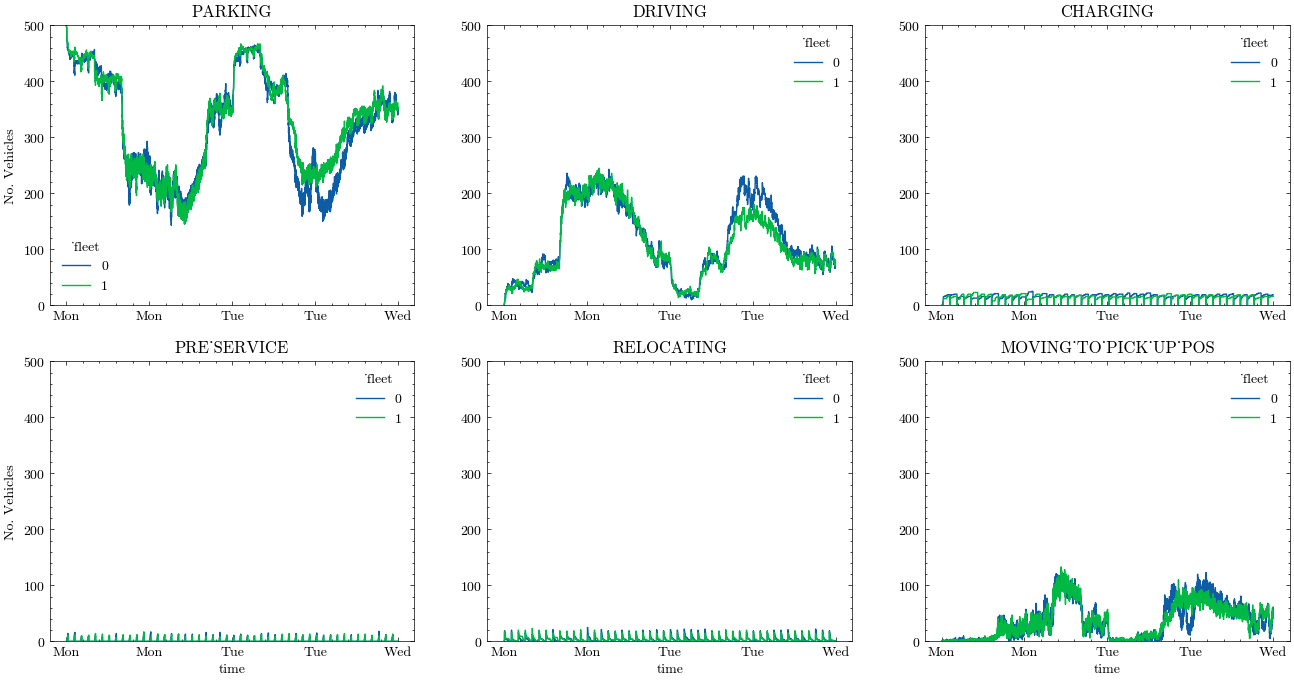

In [19]:
fig, ax = plt.subplots(nrows=2, ncols=3, figsize=(16, 8))
sns.lineplot(data=vehicle_tracking_coordinated, x='time', y='_state_PARKING', hue='_fleet', ax=ax[0][0])
sns.lineplot(data=vehicle_tracking_coordinated, x='time', y='_state_DRIVING', hue='_fleet', ax=ax[0][1])
sns.lineplot(data=vehicle_tracking_coordinated, x='time', y='_state_CHARGING', hue='_fleet', ax=ax[0][2])

sns.lineplot(data=vehicle_tracking_coordinated, x='time', y='_state_PRE_SERVICE', hue='_fleet', ax=ax[1][0])
sns.lineplot(data=vehicle_tracking_coordinated, x='time', y='_state_RELOCATING', hue='_fleet', ax=ax[1][1])
sns.lineplot(data=vehicle_tracking_coordinated, x='time', y='_state_MOVING_TO_PICK_UP_POS', hue='_fleet', ax=ax[1][2])

ax[0][0].set_title('PARKING')
ax[0][1].set_title('DRIVING')
ax[0][2].set_title('CHARGING')

ax[1][0].set_title('PRE_SERVICE')
ax[1][1].set_title('RELOCATING')
ax[1][2].set_title('MOVING_TO_PICK_UP_POS')


for aa in ax:
    for i, a in enumerate(aa):
        a.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=SIM_DAYS))
        a.xaxis.set_major_formatter(mdates.DateFormatter('%a'))


        a.set_ylabel('No. Vehicles')
        a.set_ylim(0, parser.getint("EXPERIMENT_MANAGEMENT", "N_CARS"))
        a.yaxis.label.set_visible(False) if i > 0 else None

for a in ax[0]:
    a.xaxis.label.set_visible(False)

## Charging Stations

In [20]:
charging_station_tracking_coordinated = pd.read_csv(f"data/output/tracking/{RUN_COORDINATED}_charging_stations.csv")

In [21]:
CHARGING_STATION_CAPACITY = parser.getint("CHARGING_INFRASTRUCTURE", "CHARGING_STATION_CAPACITY")

In [22]:
charging_station_tracking_coordinated['utilization'] = charging_station_tracking_coordinated['_plugs.count'] / CHARGING_STATION_CAPACITY

charging_station_tracking_coordinated['system_wide_utilization'] = charging_station_tracking_coordinated.groupby('time')['utilization'].transform('mean')

In [23]:
# rename time axis
charging_station_tracking_coordinated['time'] = pd.to_datetime(charging_station_tracking_coordinated['time'].apply(SimulationTimeConverter.as_datetime))

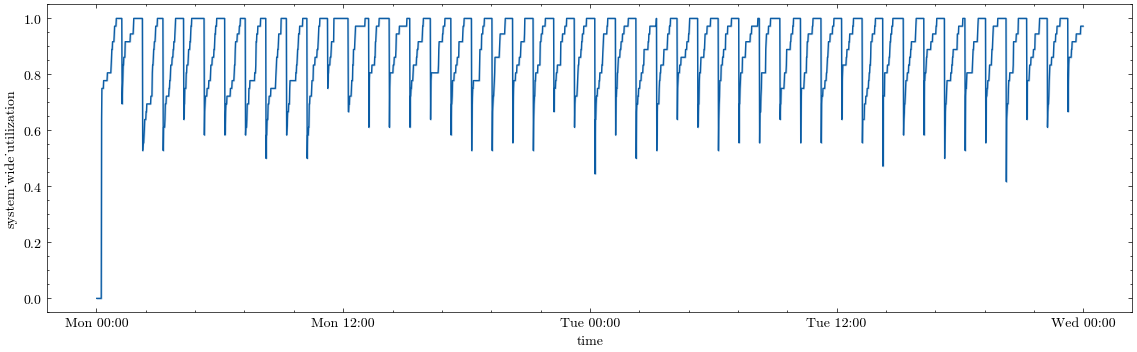

In [24]:
fig, ax = plt.subplots(1,1, figsize=(14,4))

sns.lineplot(data=charging_station_tracking_coordinated, x='time', y='system_wide_utilization', ax=ax)

ax.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=SIM_DAYS * 2))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%a %H:%M'))

/Users/janik/miniconda3/envs/urban-mobility-simulation/lib/python3.9/site-packages/IPython/core/events.py:82: UserWarning: AutoDateLocator was unable to pick an appropriate interval for this date range. It may be necessary to add an interval value to the AutoDateLocator's intervald dictionary. Defaulting to 12.
  func(*args, **kwargs)
/Users/janik/miniconda3/envs/urban-mobility-simulation/lib/python3.9/site-packages/IPython/core/pylabtools.py:152: UserWarning: AutoDateLocator was unable to pick an appropriate interval for this date range. It may be necessary to add an interval value to the AutoDateLocator's intervald dictionary. Defaulting to 12.
  fig.canvas.print_figure(bytes_io, **kw)


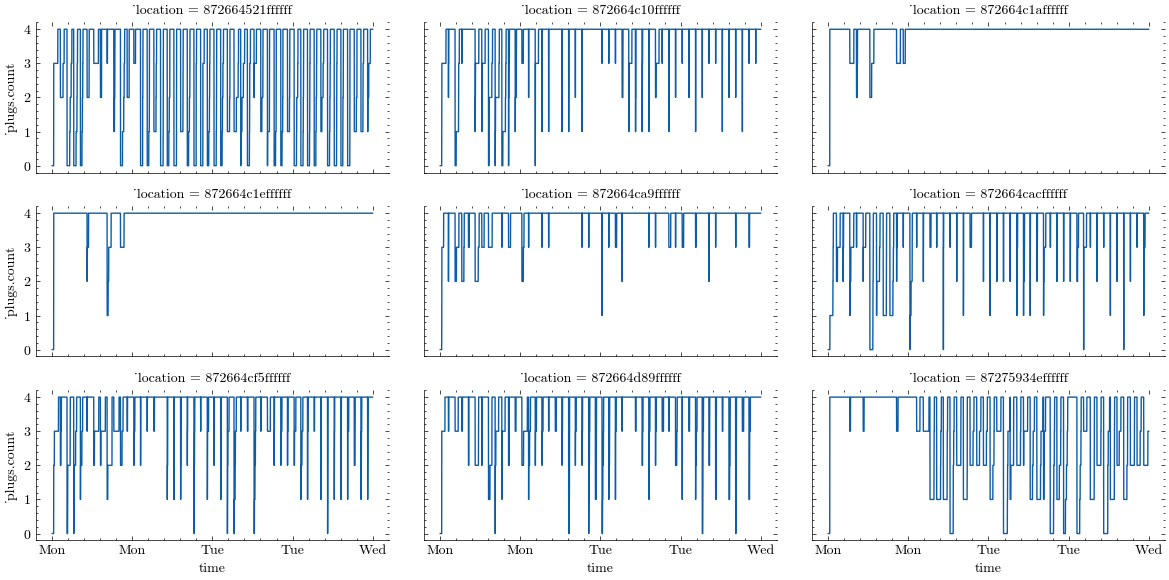

In [25]:
charging_station_tracking_coordinated.sort_values(by=['time', '_location'], inplace=True)
g = sns.relplot(
    data=charging_station_tracking_coordinated, x='time', y='_plugs.count', col='_location', kind='line', col_wrap=3, height=2, aspect=2)

axes = g.axes.flat

for a in axes:
    a.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=SIM_DAYS))
    a.xaxis.set_major_formatter(mdates.DateFormatter('%a'))

In [26]:
# fig, ax = plt.subplots(1,1, figsize=(8,4))

# sns.lineplot(data=charging_station_tracking_coordinated, x='time', y='_plugs.count', label='util', ax=ax)
# sns.lineplot(data=charging_station_tracking_coordinated, x='time', y='_plugs.queuesize', label='queue size', ax=ax)

# ax.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=SIM_DAYS * 2))
# ax.xaxis.set_major_formatter(mdates.DateFormatter('%a %H:%M'))

## Transactions

In [27]:
transactions_fleet_0 = pd.read_csv(f"data/output/transactions/{RUN_COORDINATED}_fleet_0_transactions.csv")
transactions_fleet_1 = pd.read_csv(f"data/output/transactions/{RUN_COORDINATED}_fleet_1_transactions.csv")

In [28]:
RESAMPLE_RATE = '1h'

In [29]:
transactions_fleet_0['timestamp'] = transactions_fleet_0['time_end'].apply(SimulationTimeConverter.as_datetime)
transactions_fleet_0['timestamp'] = pd.to_datetime(transactions_fleet_0['timestamp'])
transactions_fleet_0_resampled = transactions_fleet_0.resample(RESAMPLE_RATE, on = 'timestamp').agg({'state': 'value_counts'}).unstack()

transactions_fleet_1['timestamp'] = transactions_fleet_1['time_end'].apply(SimulationTimeConverter.as_datetime)
transactions_fleet_1['timestamp'] = pd.to_datetime(transactions_fleet_1['timestamp'])
transactions_fleet_1_resampled = transactions_fleet_1.resample(RESAMPLE_RATE, on = 'timestamp').agg({'state': 'value_counts'}).unstack()

In [30]:
# normalize
transactions_fleet_0_resampled = transactions_fleet_0_resampled.div(transactions_fleet_0_resampled.sum(axis=1), axis=0)

transactions_fleet_1_resampled = transactions_fleet_1_resampled.div(transactions_fleet_1_resampled.sum(axis=1), axis=0)

# rename time axis
# transactions_fleet_0_resampled['timestamp'] = transactions_fleet_0_resampled.index.strftime("%H:%M")
# transactions_fleet_0_resampled.set_index('timestamp', inplace=True)

# transactions_fleet_1_resampled['timestamp'] = transactions_fleet_1_resampled.index.strftime("%H:%M")
# transactions_fleet_1_resampled.set_index('timestamp', inplace=True)

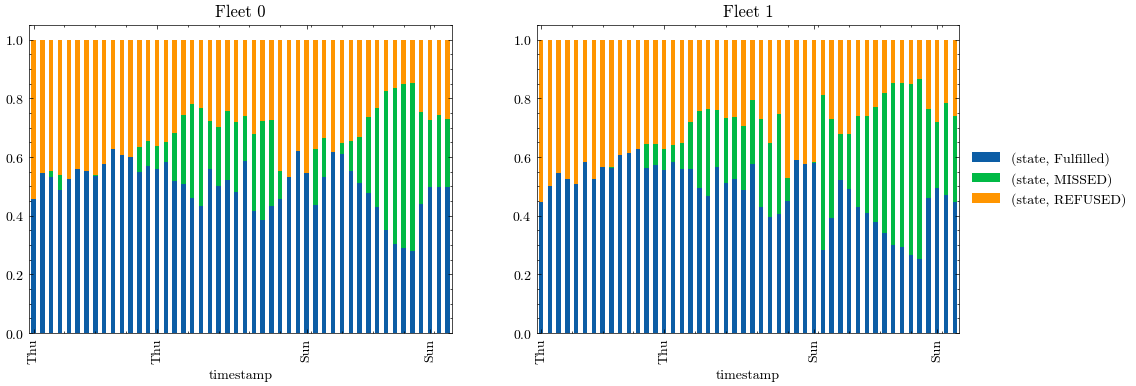

In [31]:
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(12, 4))

transactions_fleet_0_resampled.plot(kind = 'bar', stacked=True, ax=ax[0], legend=False)
transactions_fleet_1_resampled.plot(kind = 'bar', stacked=True, ax=ax[1], legend=True)

ax[1].legend(loc='center left', bbox_to_anchor=(1.0, 0.5))

ax[0].set_title('Fleet 0')
ax[1].set_title('Fleet 1')

for a in ax:
    a.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=SIM_DAYS))
    a.xaxis.set_major_formatter(mdates.DateFormatter('%a'))

(0.0, 1.0)

/Users/janik/miniconda3/envs/urban-mobility-simulation/lib/python3.9/site-packages/IPython/core/events.py:82: UserWarning: AutoDateLocator was unable to pick an appropriate interval for this date range. It may be necessary to add an interval value to the AutoDateLocator's intervald dictionary. Defaulting to 12.
  func(*args, **kwargs)
/Users/janik/miniconda3/envs/urban-mobility-simulation/lib/python3.9/site-packages/IPython/core/pylabtools.py:152: UserWarning: AutoDateLocator was unable to pick an appropriate interval for this date range. It may be necessary to add an interval value to the AutoDateLocator's intervald dictionary. Defaulting to 12.
  fig.canvas.print_figure(bytes_io, **kw)


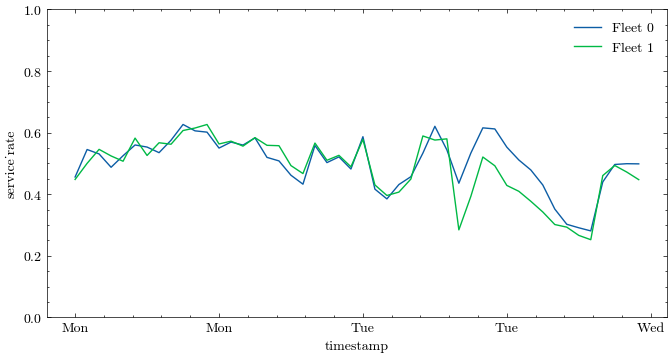

In [32]:
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(8, 4))

transactions_fleet_0_resampled['service_rate'] = transactions_fleet_0_resampled[('state', 'Fulfilled')]
transactions_fleet_1_resampled['service_rate'] = transactions_fleet_1_resampled[('state', 'Fulfilled')]

# service_rate_mean = transactions_fleet_0_resampled.reset_index()[['timestamp', 'service_rate']].join(transactions_fleet_1_resampled.reset_index()[['timestamp', 'service_rate']], on='timestamp')

sns.lineplot(data=transactions_fleet_0_resampled, x = transactions_fleet_0_resampled.index, y = 'service_rate', label='Fleet 0', ax=ax)
sns.lineplot(data=transactions_fleet_1_resampled, x = transactions_fleet_1_resampled.index, y = 'service_rate', label='Fleet 1', ax=ax)

ax.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=SIM_DAYS))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%a'))

ax.set_ylim(0, 1.0)

### Vehilce Distance Travelled: Service vs. Operations

In [33]:
vehicle_tracking_coordinated['fleet_vdt'] = vehicle_tracking_coordinated['_vdt'].apply(lambda x: sum(eval(x)))

In [34]:
service_vdt_fleet_0 = transactions_fleet_0[transactions_fleet_0['state'] == 'Fulfilled'].resample(RESAMPLE_RATE, on = 'timestamp').agg({'distance': 'sum'})
service_vdt_fleet_1 = transactions_fleet_1[transactions_fleet_1['state'] == 'Fulfilled'].resample(RESAMPLE_RATE, on = 'timestamp').agg({'distance': 'sum'})

In [35]:
service_vdt_fleet_0['cumsum'] = service_vdt_fleet_0.cumsum()
service_vdt_fleet_1['cumsum'] = service_vdt_fleet_1.cumsum()

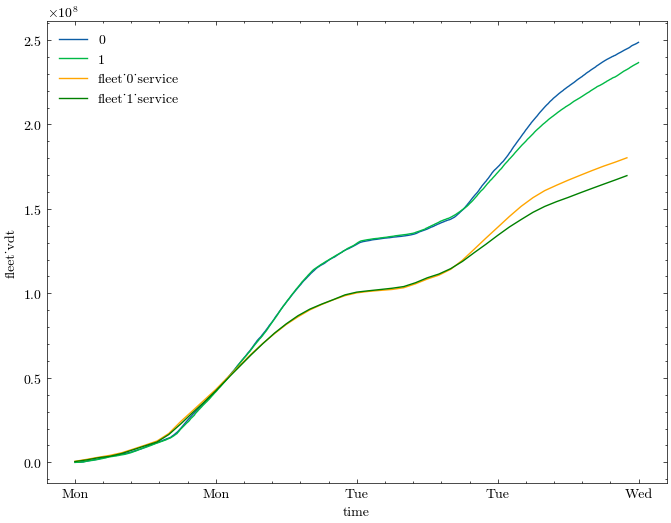

In [36]:
fig, ax = plt.subplots(1,1, figsize=(8, 6))

sns.lineplot(data=vehicle_tracking_coordinated, x='time', y='fleet_vdt', hue='_fleet', ax=ax)
sns.lineplot(data=service_vdt_fleet_0, x='timestamp', y='cumsum', color='orange', label='fleet_0_service', ax=ax)
sns.lineplot(data=service_vdt_fleet_1, x='timestamp', y='cumsum', color='green', label='fleet_1_service', ax=ax)

ax.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=SIM_DAYS * 2))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%a'))

In [37]:
# share of operations VDT (excl customer serving)
hourly_vdt = vehicle_tracking_coordinated.groupby('_fleet').resample(RESAMPLE_RATE, on = 'time').agg({'fleet_vdt': 'max'}).unstack(level=0).rename(columns={0: 'fleet_0_vdt_cumsum', 1: 'fleet_1_vdt_cumsum'}).droplevel(0, axis=1)

In [38]:
hourly_vdt = hourly_vdt.join(service_vdt_fleet_0)

hourly_vdt = hourly_vdt.join(service_vdt_fleet_1, rsuffix='_service_fleet_1')

hourly_vdt.rename(columns={'distance': 'distance_service_fleet_0', 'cumsum': 'cumsum_service_fleet_0'}, inplace=True)

hourly_vdt['fleet_0_ratio_of_empty_vdt'] = (hourly_vdt['fleet_0_vdt_cumsum'] - hourly_vdt['cumsum_service_fleet_0']) / hourly_vdt['fleet_0_vdt_cumsum']

hourly_vdt['fleet_1_ratio_of_empty_vdt'] = (hourly_vdt['fleet_1_vdt_cumsum'] - hourly_vdt['cumsum_service_fleet_1']) / hourly_vdt['fleet_1_vdt_cumsum']

In [39]:
hourly_vdt['fleet_0_vdt'] = hourly_vdt['fleet_0_vdt_cumsum'].diff().fillna(hourly_vdt['fleet_0_vdt_cumsum'].iloc[0])

hourly_vdt['fleet_1_vdt'] = hourly_vdt['fleet_1_vdt_cumsum'].diff().fillna(hourly_vdt['fleet_1_vdt_cumsum'].iloc[0])


In [40]:
hourly_vdt['fleet_0_ratio_of_empty_vdt'] = (hourly_vdt['fleet_0_vdt'] - hourly_vdt['distance_service_fleet_0']) / hourly_vdt['fleet_0_vdt']

hourly_vdt['fleet_1_ratio_of_empty_vdt'] = (hourly_vdt['fleet_1_vdt'] - hourly_vdt['distance_service_fleet_1']) / hourly_vdt['fleet_1_vdt']

In [41]:
hourly_vdt.head()

,fleet_0_vdt_cumsum,fleet_1_vdt_cumsum,distance_service_fleet_0,cumsum_service_fleet_0,distance_service_fleet_1,cumsum_service_fleet_1,fleet_0_ratio_of_empty_vdt,fleet_1_ratio_of_empty_vdt,fleet_0_vdt,fleet_1_vdt
time,,,,,,,,,,
2024-01-01 00:00:00,7.115081e+05,6.478679e+05,5.910072e+05,5.910072e+05,4.756626e+05,4.756626e+05,0.169360,0.265803,7.115081e+05,6.478679e+05
2024-01-01 01:00:00,1.983528e+06,1.753005e+06,1.170122e+06,1.761130e+06,9.732707e+05,1.448933e+06,0.080107,0.119321,1.272020e+06,1.105137e+06
2024-01-01 02:00:00,3.512985e+06,3.307500e+06,1.250153e+06,3.011283e+06,1.286537e+06,2.735470e+06,0.182616,0.172376,1.529457e+06,1.554495e+06
2024-01-01 03:00:00,4.895911e+06,4.425684e+06,1.151941e+06,4.163224e+06,9.087215e+05,3.644192e+06,0.167026,0.187324,1.382926e+06,1.118184e+06
2024-01-01 04:00:00,6.532209e+06,6.243194e+06,1.527601e+06,5.690825e+06,1.625228e+06,5.269420e+06,0.066429,0.105794,1.636298e+06,1.817510e+06


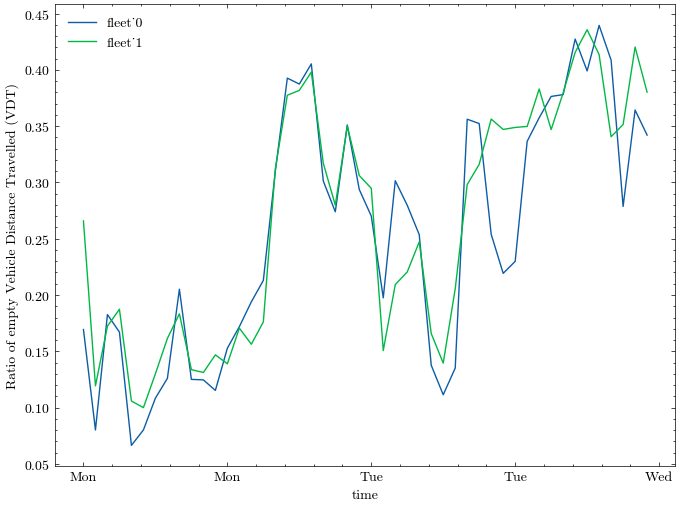

In [42]:
fig, ax = plt.subplots(1,1, figsize=(8, 6))

sns.lineplot(data=hourly_vdt, x='time', y='fleet_0_ratio_of_empty_vdt', label='fleet_0', ax=ax)
sns.lineplot(data=hourly_vdt, x='time', y='fleet_1_ratio_of_empty_vdt', label='fleet_1', ax=ax)

ax.set_ylabel('Ratio of empty Vehicle Distance Travelled (VDT)')

ax.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=SIM_DAYS * 2))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%a'))

## Service Tasks

In [43]:
task_transactions_fleet_0 = pd.read_csv(f"data/output/transactions/{RUN_COORDINATED}_fleet_0_task_transactions.csv")

task_transactions_fleet_1 = pd.read_csv(f"data/output/transactions/{RUN_COORDINATED}_fleet_1_task_transactions.csv")

In [44]:
task_transactions_fleet_0['timestamp'] = task_transactions_fleet_0['start_time'].apply(SimulationTimeConverter.as_datetime)
task_transactions_fleet_0['timestamp'] = pd.to_datetime(task_transactions_fleet_0['timestamp'])

task_transactions_fleet_1['timestamp'] = task_transactions_fleet_1['start_time'].apply(SimulationTimeConverter.as_datetime)
task_transactions_fleet_1['timestamp'] = pd.to_datetime(task_transactions_fleet_1['timestamp'])

task_transactions_fleet_0['duration'] = task_transactions_fleet_0['end_time'] - task_transactions_fleet_0['start_time']

task_transactions_fleet_1['duration'] = task_transactions_fleet_1['end_time'] - task_transactions_fleet_1['start_time']

!! probably we should sanity-check why duration < waiting_time + charging_duration

In [45]:
task_transactions_fleet_0

,start_time,scheduled_time,end_time,vehicle,state,fleet,charging_station,waiting_time,charging_duration,kWh_charged,timestamp,duration
0,6,15,74.999999,21,TaskState.FINISHED,0,872664521ffffff,7.856300,59.999999,22.000000,2024-01-01 00:06:00,68.999999
1,6,15,74.999999,431,TaskState.FINISHED,0,87275934effffff,7.711217,59.999999,22.000000,2024-01-01 00:06:00,68.999999
2,6,15,74.999999,155,TaskState.FINISHED,0,872664c1effffff,7.370070,59.999999,22.000000,2024-01-01 00:06:00,68.999999
3,6,15,74.999999,23,TaskState.FINISHED,0,872664521ffffff,7.266630,59.999999,22.000000,2024-01-01 00:06:00,68.999999
4,6,15,74.999999,473,TaskState.FINISHED,0,87275934effffff,7.118383,59.999999,22.000000,2024-01-01 00:06:00,68.999999
...,...,...,...,...,...,...,...,...,...,...,...,...
893,2826,2835,2880.000000,488,TaskState.EXECUTING_CHARGING,0,872664cacffffff,-0.147203,59.852796,21.946025,2024-01-02 23:06:00,54.000000
894,2826,2835,2880.000000,99,TaskState.EXECUTING_CHARGING,0,872664cf5ffffff,-0.614297,59.385702,21.774757,2024-01-02 23:06:00,54.000000
895,2826,2835,2880.000000,284,TaskState.EXECUTING_CHARGING,0,872664d89ffffff,6.781583,59.999999,22.000000,2024-01-02 23:06:00,54.000000
896,2826,2835,2880.000000,217,TaskState.EXECUTING_CHARGING,0,87275934effffff,-36.197888,23.802111,8.727441,2024-01-02 23:06:00,54.000000


In [46]:
display(task_transactions_fleet_0.value_counts(subset=['state']))
display(task_transactions_fleet_1.value_counts(subset=['state']))

state                       
TaskState.FINISHED              879
TaskState.EXECUTING_CHARGING     19
Name: count, dtype: int64

state                         
TaskState.FINISHED                813
TaskState.EXECUTING_CHARGING       16
TaskState.EXECUTING_RELOCATION      1
Name: count, dtype: int64

/Users/janik/miniconda3/envs/urban-mobility-simulation/lib/python3.9/site-packages/IPython/core/events.py:82: UserWarning: AutoDateLocator was unable to pick an appropriate interval for this date range. It may be necessary to add an interval value to the AutoDateLocator's intervald dictionary. Defaulting to 12.
  func(*args, **kwargs)
/Users/janik/miniconda3/envs/urban-mobility-simulation/lib/python3.9/site-packages/IPython/core/pylabtools.py:152: UserWarning: AutoDateLocator was unable to pick an appropriate interval for this date range. It may be necessary to add an interval value to the AutoDateLocator's intervald dictionary. Defaulting to 12.
  fig.canvas.print_figure(bytes_io, **kw)


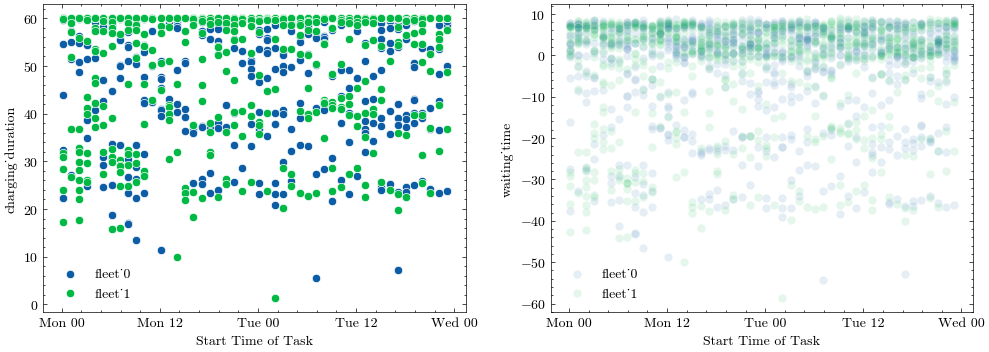

In [47]:
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(12, 4))

sns.scatterplot(data=task_transactions_fleet_0, x='timestamp', y='charging_duration', label='fleet_0', ax=ax[0])
sns.scatterplot(data=task_transactions_fleet_1, x='timestamp', y='charging_duration', label='fleet_1', ax=ax[0])

sns.scatterplot(data=task_transactions_fleet_0, x='timestamp', y='waiting_time', label='fleet_0', ax=ax[1], alpha=.1)
sns.scatterplot(data=task_transactions_fleet_1, x='timestamp', y='waiting_time', label='fleet_1', ax=ax[1], alpha=.1)

for a in ax:
    a.set_xlabel('Start Time of Task')
    a.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=SIM_DAYS))
    a.xaxis.set_major_formatter(mdates.DateFormatter('%a %H'))

<Axes: xlabel='waiting_time', ylabel='Density'>

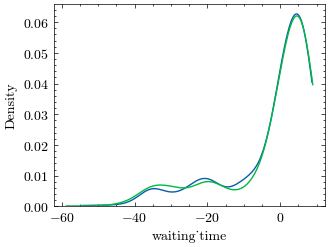

In [48]:
sns.kdeplot(data=task_transactions_fleet_0, x='waiting_time', label='fleet_0', cut=0)
sns.kdeplot(data=task_transactions_fleet_1, x='waiting_time', label='fleet_1',cut=0)

In [49]:
hourly_tasks = pd.merge(
    task_transactions_fleet_0.resample('h', on='timestamp').agg({'fleet': 'count', 'waiting_time': 'mean', 'charging_duration': 'mean'}).rename(columns={'fleet': 'tasks_finished_fleet_0', 'waiting_time': 'avg_waiting_time_fleet_0', 'charging_duration': 'avg_charging_duration_fleet_0'}),
    task_transactions_fleet_1.resample('h', on='timestamp').agg({'fleet': 'count', 'waiting_time': 'mean', 'charging_duration': 'mean'}).rename(columns={'fleet': 'tasks_finished_fleet_1', 'waiting_time': 'avg_waiting_time_fleet_1', 'charging_duration': 'avg_charging_duration_fleet_1'}),
    how='outer',
    left_index=True,
    right_index=True
).fillna(0)

/Users/janik/miniconda3/envs/urban-mobility-simulation/lib/python3.9/site-packages/IPython/core/events.py:82: UserWarning: AutoDateLocator was unable to pick an appropriate interval for this date range. It may be necessary to add an interval value to the AutoDateLocator's intervald dictionary. Defaulting to 12.
  func(*args, **kwargs)
/Users/janik/miniconda3/envs/urban-mobility-simulation/lib/python3.9/site-packages/IPython/core/pylabtools.py:152: UserWarning: AutoDateLocator was unable to pick an appropriate interval for this date range. It may be necessary to add an interval value to the AutoDateLocator's intervald dictionary. Defaulting to 12.
  fig.canvas.print_figure(bytes_io, **kw)


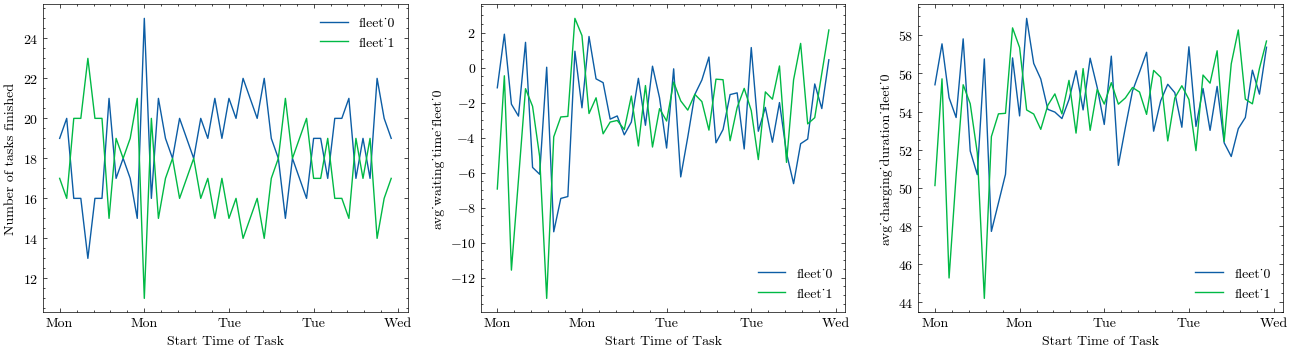

In [50]:
fig, ax = plt.subplots(nrows=1, ncols=3, figsize=(16, 4))

sns.lineplot(data=hourly_tasks, x='timestamp', y='tasks_finished_fleet_0', label='fleet_0', ax=ax[0])
sns.lineplot(data=hourly_tasks, x='timestamp', y='tasks_finished_fleet_1', label='fleet_1', ax=ax[0])

sns.lineplot(data=hourly_tasks, x='timestamp', y='avg_waiting_time_fleet_0', label='fleet_0', ax=ax[1])
sns.lineplot(data=hourly_tasks, x='timestamp', y='avg_waiting_time_fleet_1', label='fleet_1', ax=ax[1])

sns.lineplot(data=hourly_tasks, x='timestamp', y='avg_charging_duration_fleet_0', label='fleet_0', ax=ax[2])
sns.lineplot(data=hourly_tasks, x='timestamp', y='avg_charging_duration_fleet_1', label='fleet_1', ax=ax[2])

ax[0].set_ylabel("Number of tasks finished")

for a in ax:
    a.set_xlabel('Start Time of Task')
    a.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=SIM_DAYS + 1))
    a.xaxis.set_major_formatter(mdates.DateFormatter('%a'))

In [51]:
date_range = range(0,parser.getint("EXPERIMENT_MANAGEMENT", "END_TIME"), 15)

hourly_events_fleet_0 = pd.DataFrame({'time': date_range, 'events_ongoing_fleet_0': [((task_transactions_fleet_0['start_time'] <= i) & (task_transactions_fleet_0['end_time'] > i)).sum() for i in date_range]})
hourly_events_fleet_0.set_index('time', inplace=True)

hourly_events_fleet_1 = pd.DataFrame({'time': date_range, 'events_ongoing_fleet_1': [((task_transactions_fleet_1['start_time'] <= i) & (task_transactions_fleet_1['end_time'] > i)).sum() for i in date_range]})
hourly_events_fleet_1.set_index('time', inplace=True)

hourly_events_ongoing = pd.merge(
    hourly_events_fleet_0,
    hourly_events_fleet_1,
    how='outer',
    left_index=True,
    right_index=True
).fillna(0)

hourly_events_ongoing.reset_index(inplace=True)

In [52]:
hourly_events_ongoing['timestamp'] = hourly_events_ongoing['time'].apply(SimulationTimeConverter.as_datetime)
hourly_events_ongoing['timestamp'] = pd.to_datetime(hourly_events_ongoing['timestamp'])

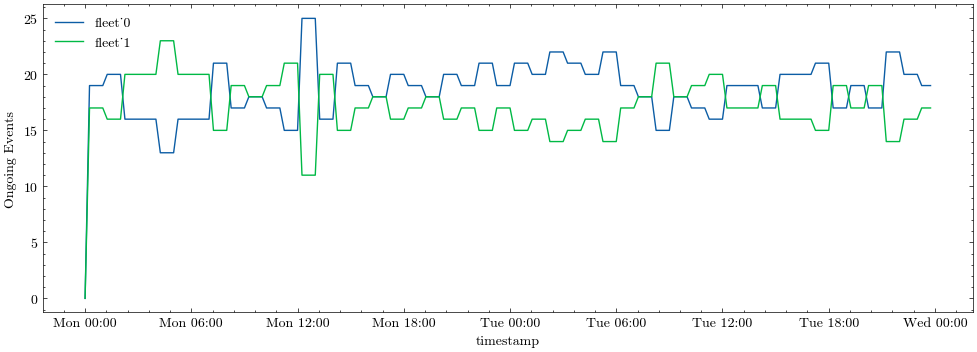

In [53]:
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(12, 4))

sns.lineplot(data=hourly_events_ongoing, x='timestamp', y='events_ongoing_fleet_0', label='fleet_0', ax=ax)
sns.lineplot(data=hourly_events_ongoing, x='timestamp', y='events_ongoing_fleet_1', label='fleet_1', ax=ax)

ax.set_ylabel('Ongoing Events')

ax.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=12))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%a %H:%M'))


In [54]:
task_transactions_fleet_0['timeslot'] = (task_transactions_fleet_0['end_time'] - task_transactions_fleet_0['charging_duration']) - ((task_transactions_fleet_0['end_time'] - task_transactions_fleet_0['charging_duration']) % 15)

task_transactions_fleet_1['timeslot'] = (task_transactions_fleet_1['end_time'] - task_transactions_fleet_1['charging_duration']) - ((task_transactions_fleet_1['end_time'] - task_transactions_fleet_1['charging_duration']) % 15)

In [55]:
tasks_incl_price = pd.concat(
    [task_transactions_fleet_0,task_transactions_fleet_1]
    ).merge(
        auction_tracking[['time', '_result.clearing_price']], 
        how='left', 
        left_on = 'timeslot', 
        right_on = "time"
        )

NameError: name 'auction_tracking' is not defined

In [ ]:
kWh_price = parser.getfloat("AUTONOMOUS_CAR", "CHARGING_COST_PER_KWH")

tasks_incl_price['charging_cost'] = tasks_incl_price['kWh_charged'] * kWh_price

In [ ]:
tasks_incl_price.head()

,start_time,scheduled_time,end_time,vehicle,state,fleet,charging_station,waiting_time,charging_duration,kWh_charged,timestamp,duration,timeslot,time,_result.clearing_price,charging_cost
0,6,20,79.999999,493,TaskState.FINISHED,0,87275934effffff,13.702930,59.999999,22.0,2024-01-01 00:06:00,73.999999,15.0,NaN,NaN,9.46
1,6,20,79.999999,179,TaskState.FINISHED,0,872664c1effffff,13.302421,59.999999,22.0,2024-01-01 00:06:00,73.999999,15.0,NaN,NaN,9.46
2,6,20,79.999999,86,TaskState.FINISHED,0,872664c1affffff,13.132427,59.999999,22.0,2024-01-01 00:06:00,73.999999,15.0,NaN,NaN,9.46
3,6,20,79.999999,112,TaskState.FINISHED,0,872664c1affffff,13.097513,59.999999,22.0,2024-01-01 00:06:00,73.999999,15.0,NaN,NaN,9.46
4,6,20,79.999999,14,TaskState.FINISHED,0,872664521ffffff,11.790715,59.999999,22.0,2024-01-01 00:06:00,73.999999,15.0,NaN,NaN,9.46


In [ ]:
hourly_costs = tasks_incl_price.groupby('fleet').resample('1h', on='timestamp').agg({'charging_cost': 'sum', '_result.clearing_price': 'sum'}).reset_index()
hourly_costs.rename(columns={'_result.clearing_price': 'reservation_cost'}, inplace=True)

/Users/janik/miniconda3/envs/urban-mobility-simulation/lib/python3.9/site-packages/IPython/core/events.py:82: UserWarning: Glyph 8364 (\N{EURO SIGN}) missing from current font.
  func(*args, **kwargs)
/Users/janik/miniconda3/envs/urban-mobility-simulation/lib/python3.9/site-packages/IPython/core/pylabtools.py:152: UserWarning: Glyph 8364 (\N{EURO SIGN}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


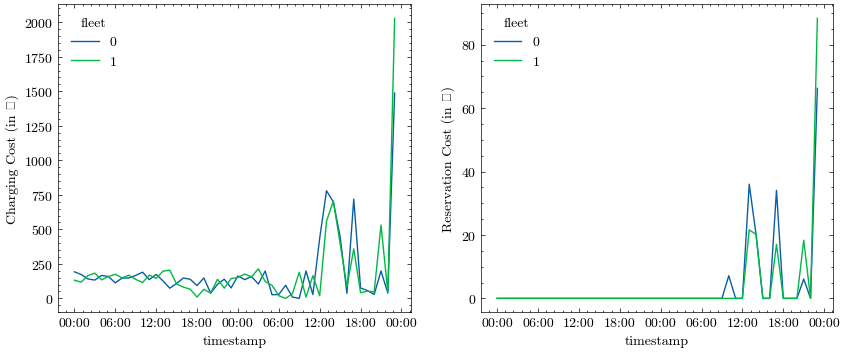

In [ ]:
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(10, 4))

sns.lineplot(hourly_costs, x='timestamp', y='charging_cost', hue='fleet', ax=ax[0])
sns.lineplot(hourly_costs, x='timestamp', y='reservation_cost', hue='fleet', ax=ax[1])

ax[0].set_ylabel('Charging Cost (in €)')
ax[1].set_ylabel('Reservation Cost (in €)')

for a in ax:
    a.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=12))
    a.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))

## Benchmarks: Single Infrastructure, No Coordination // Seperate Infrastructures

In [62]:
charging_station_tracking_uncoordinated = pd.read_csv(f"data/output/tracking/{RUN_UNCOORDINATED}_charging_stations.csv")
vehicle_tracking_uncoordinated = pd.read_csv(f"data/output/tracking/{RUN_UNCOORDINATED}_vehicles.csv")

charging_station_tracking_seperate = pd.read_csv(f"data/output/tracking/{RUN_SEPERATE}_charging_stations.csv")
vehicle_tracking_seperate = pd.read_csv(f"data/output/tracking/{RUN_SEPERATE}_vehicles.csv")

In [63]:
# rename time axis
vehicle_tracking_uncoordinated.rename(columns={'time': 'simtime'}, inplace=True)
vehicle_tracking_uncoordinated['time'] = pd.to_datetime(vehicle_tracking_uncoordinated['simtime'].apply(SimulationTimeConverter.as_datetime))

vehicle_tracking_seperate.rename(columns={'time': 'simtime'}, inplace=True)
vehicle_tracking_seperate['time'] = pd.to_datetime(vehicle_tracking_seperate['simtime'].apply(SimulationTimeConverter.as_datetime))

# vehicle_tracking_coordinated['timestamp'] = vehicle_tracking_coordinated['time'].dt.strftime("%H:%M")

In [64]:
vehicle_tracking_uncoordinated['fleet_average_SOC'] = vehicle_tracking_uncoordinated['_current_state_of_charge'].apply(lambda x: np.mean(eval(x))) / parser.getfloat("AUTONOMOUS_CAR", "MAX_STATE_OF_CHARGE")
vehicle_tracking_uncoordinated['hour'] = vehicle_tracking_uncoordinated['simtime'].apply(lambda x: SimulationTimeConverter.hours(int(x)))
vehicle_tracking_uncoordinated['fleet_number_low_SOC'] = vehicle_tracking_uncoordinated.apply(lambda x: np.count_nonzero(np.array(eval(x['_current_state_of_charge'])) < RECHARGE_THRESHOLD[x['hour']]), axis=1)

vehicle_tracking_seperate['fleet_average_SOC'] = vehicle_tracking_seperate['_current_state_of_charge'].apply(lambda x: np.mean(eval(x))) / parser.getfloat("AUTONOMOUS_CAR", "MAX_STATE_OF_CHARGE")
vehicle_tracking_seperate['hour'] = vehicle_tracking_seperate['simtime'].apply(lambda x: SimulationTimeConverter.hours(int(x)))
vehicle_tracking_seperate['fleet_number_low_SOC'] = vehicle_tracking_seperate.apply(lambda x: np.count_nonzero(np.array(eval(x['_current_state_of_charge'])) < RECHARGE_THRESHOLD[x['hour']]), axis=1)

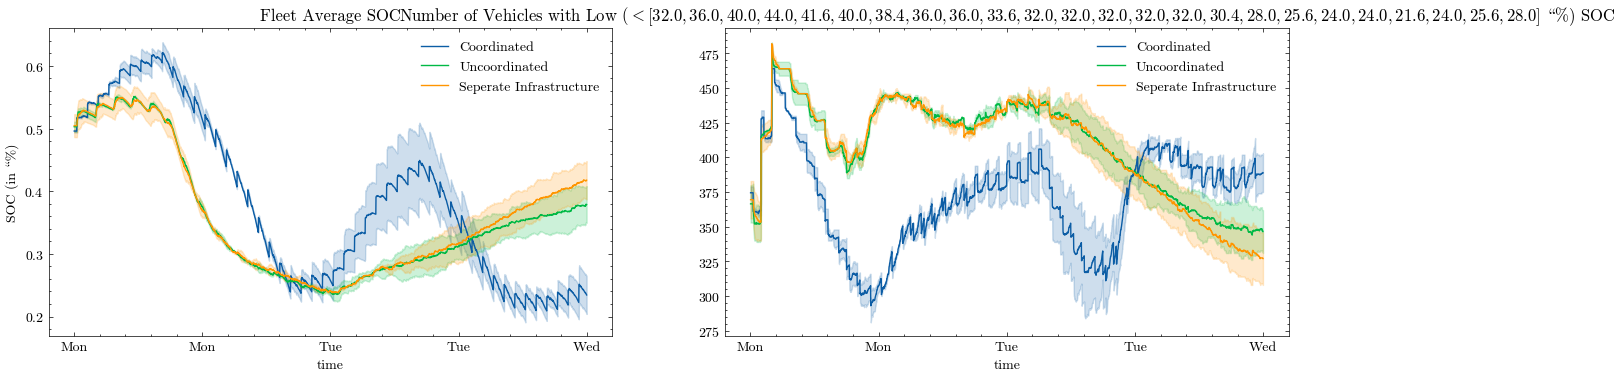

In [65]:
fig, ax = plt.subplots(nrows = 1, ncols = 2, figsize = (16, 4))

sns.lineplot(data=vehicle_tracking_coordinated, x='time', y='fleet_average_SOC', ax = ax[0], label='Coordinated')
sns.lineplot(data=vehicle_tracking_uncoordinated, x='time', y='fleet_average_SOC', ax = ax[0], label='Uncoordinated')
sns.lineplot(data=vehicle_tracking_seperate, x='time', y='fleet_average_SOC', ax = ax[0], label='Seperate Infrastructure')

sns.lineplot(data=vehicle_tracking_coordinated, x='time', y='fleet_number_low_SOC', ax = ax[1], label='Coordinated')
sns.lineplot(data=vehicle_tracking_uncoordinated, x='time', y='fleet_number_low_SOC', ax = ax[1], label='Uncoordinated')
sns.lineplot(data=vehicle_tracking_seperate, x='time', y='fleet_number_low_SOC', ax = ax[1], label='Seperate Infrastructure')

ax[0].set_title('Fleet Average SOC')
ax[0].set_ylabel('SOC (in \%)')
ax[1].set_title(f'No. Vehicles Fleet with Low (time-dependent) SOC')
ax[1].set_ylabel('')

for a in ax:
    a.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=SIM_DAYS * 2))
    a.xaxis.set_major_formatter(mdates.DateFormatter('%a'))

plt.show()

In [66]:
charging_station_tracking_uncoordinated['utilization'] = charging_station_tracking_uncoordinated['_plugs.count'] / CHARGING_STATION_CAPACITY
charging_station_tracking_uncoordinated['system_wide_utilization'] = charging_station_tracking_uncoordinated.groupby('time')['utilization'].transform('mean')

charging_station_tracking_seperate['utilization'] = charging_station_tracking_seperate['_plugs.count'] / (CHARGING_STATION_CAPACITY / 2)
charging_station_tracking_seperate['system_wide_utilization'] = charging_station_tracking_seperate.groupby('time')['utilization'].transform('mean')

In [67]:
# rename time axis
charging_station_tracking_uncoordinated['time'] = pd.to_datetime(charging_station_tracking_uncoordinated['time'].apply(SimulationTimeConverter.as_datetime))
charging_station_tracking_seperate['time'] = pd.to_datetime(charging_station_tracking_seperate['time'].apply(SimulationTimeConverter.as_datetime))

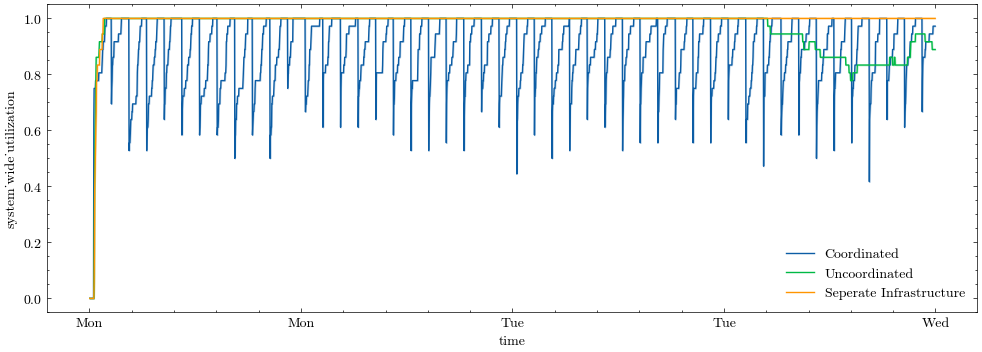

In [68]:
fig, ax = plt.subplots(1,1, figsize=(12,4))

sns.lineplot(data=charging_station_tracking_coordinated, x='time', y='system_wide_utilization', label= 'Coordinated', ax=ax)
sns.lineplot(data=charging_station_tracking_uncoordinated, x='time', y='system_wide_utilization', label= 'Uncoordinated', ax=ax)
sns.lineplot(data=charging_station_tracking_seperate, x='time', y='system_wide_utilization', label= 'Seperate Infrastructure', ax=ax)

ax.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=SIM_DAYS * 2))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%a'))

In [69]:
transactions_fleet_0_uncoordinated = pd.read_csv(f"data/output/transactions/{RUN_UNCOORDINATED}_fleet_0_transactions.csv")
transactions_fleet_1_uncoordinated = pd.read_csv(f"data/output/transactions/{RUN_UNCOORDINATED}_fleet_1_transactions.csv")

transactions_fleet_0_seperate = pd.read_csv(f"data/output/transactions/{RUN_SEPERATE}_fleet_0_transactions.csv")
transactions_fleet_1_seperate = pd.read_csv(f"data/output/transactions/{RUN_SEPERATE}_fleet_1_transactions.csv")

In [70]:
transactions_fleet_0_uncoordinated['timestamp'] = transactions_fleet_0_uncoordinated['time_end'].apply(SimulationTimeConverter.as_datetime)
transactions_fleet_0_uncoordinated['timestamp'] = pd.to_datetime(transactions_fleet_0_uncoordinated['timestamp'])
transactions_fleet_0_uncoordinated_resampled = transactions_fleet_0_uncoordinated.resample(RESAMPLE_RATE, on = 'timestamp').agg({'state': 'value_counts'}).unstack()

transactions_fleet_1_uncoordinated['timestamp'] = transactions_fleet_1_uncoordinated['time_end'].apply(SimulationTimeConverter.as_datetime)
transactions_fleet_1_uncoordinated['timestamp'] = pd.to_datetime(transactions_fleet_1_uncoordinated['timestamp'])
transactions_fleet_1_uncoordinated_resampled = transactions_fleet_1_uncoordinated.resample(RESAMPLE_RATE, on = 'timestamp').agg({'state': 'value_counts'}).unstack()

transactions_fleet_0_seperate['timestamp'] = transactions_fleet_0_seperate['time_end'].apply(SimulationTimeConverter.as_datetime)
transactions_fleet_0_seperate['timestamp'] = pd.to_datetime(transactions_fleet_0_seperate['timestamp'])
transactions_fleet_0_seperate_resampled = transactions_fleet_0_seperate.resample(RESAMPLE_RATE, on = 'timestamp').agg({'state': 'value_counts'}).unstack()

transactions_fleet_1_seperate['timestamp'] = transactions_fleet_1_seperate['time_end'].apply(SimulationTimeConverter.as_datetime)
transactions_fleet_1_seperate['timestamp'] = pd.to_datetime(transactions_fleet_1_seperate['timestamp'])
transactions_fleet_1_seperate_resampled = transactions_fleet_1_seperate.resample(RESAMPLE_RATE, on = 'timestamp').agg({'state': 'value_counts'}).unstack()


# normalize
transactions_fleet_0_uncoordinated_resampled = transactions_fleet_0_uncoordinated_resampled.div(transactions_fleet_0_uncoordinated_resampled.sum(axis=1), axis=0)
transactions_fleet_1_uncoordinated_resampled = transactions_fleet_1_uncoordinated_resampled.div(transactions_fleet_1_uncoordinated_resampled.sum(axis=1), axis=0)

transactions_fleet_0_seperate_resampled = transactions_fleet_0_seperate_resampled.div(transactions_fleet_0_seperate_resampled.sum(axis=1), axis=0)
transactions_fleet_1_seperate_resampled = transactions_fleet_1_seperate_resampled.div(transactions_fleet_1_seperate_resampled.sum(axis=1), axis=0)

# calc service rate, per fleet and overall
transactions_fleet_0_uncoordinated_resampled['service_rate'] = transactions_fleet_0_uncoordinated_resampled[('state', 'Fulfilled')]
transactions_fleet_1_uncoordinated_resampled['service_rate'] = transactions_fleet_1_uncoordinated_resampled[('state', 'Fulfilled')]

transactions_fleet_0_seperate_resampled['service_rate'] = transactions_fleet_0_seperate_resampled[('state', 'Fulfilled')]
transactions_fleet_1_seperate_resampled['service_rate'] = transactions_fleet_1_seperate_resampled[('state', 'Fulfilled')]

service_rate_coordinated = transactions_fleet_0_resampled.reset_index()[['timestamp', 'service_rate']].merge(transactions_fleet_1_resampled.reset_index()[['timestamp', 'service_rate']], on='timestamp')
service_rate_uncoordinated = transactions_fleet_0_uncoordinated_resampled.reset_index()[['timestamp', 'service_rate']].merge(transactions_fleet_1_uncoordinated_resampled.reset_index()[['timestamp', 'service_rate']], on='timestamp')
service_rate_seperate = transactions_fleet_0_seperate_resampled.reset_index()[['timestamp', 'service_rate']].merge(transactions_fleet_1_seperate_resampled.reset_index()[['timestamp', 'service_rate']], on='timestamp')

service_rate_coordinated['service_rate'] = service_rate_coordinated[['service_rate_x', 'service_rate_y']].apply('mean', axis=1)
service_rate_uncoordinated['service_rate'] = service_rate_uncoordinated[['service_rate_x', 'service_rate_y']].apply('mean', axis=1)
service_rate_seperate['service_rate'] = service_rate_seperate[['service_rate_x', 'service_rate_y']].apply('mean', axis=1)

/var/folders/tm/rzk5w14x43s6q7sgpkq2r7wc0000gn/T/ipykernel_86770/2214906733.py:32: PerformanceWarning: dropping on a non-lexsorted multi-index without a level parameter may impact performance.
  service_rate_coordinated = transactions_fleet_0_resampled.reset_index()[['timestamp', 'service_rate']].merge(transactions_fleet_1_resampled.reset_index()[['timestamp', 'service_rate']], on='timestamp')
/var/folders/tm/rzk5w14x43s6q7sgpkq2r7wc0000gn/T/ipykernel_86770/2214906733.py:33: PerformanceWarning: dropping on a non-lexsorted multi-index without a level parameter may impact performance.
  service_rate_uncoordinated = transactions_fleet_0_uncoordinated_resampled.reset_index()[['timestamp', 'service_rate']].merge(transactions_fleet_1_uncoordinated_resampled.reset_index()[['timestamp', 'service_rate']], on='timestamp')
/var/folders/tm/rzk5w14x43s6q7sgpkq2r7wc0000gn/T/ipykernel_86770/2214906733.py:34: PerformanceWarning: dropping on a non-lexsorted multi-index without a level parameter may imp

(0.0, 1.0)

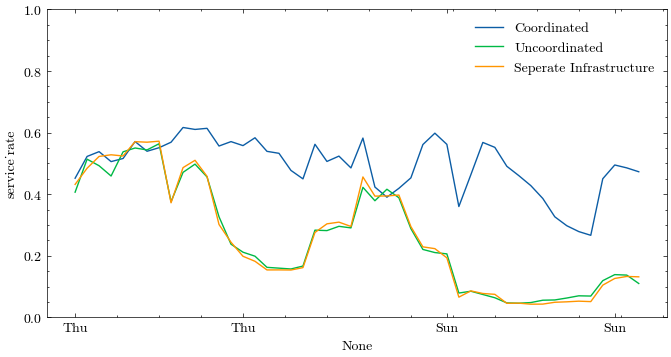

In [71]:
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(8, 4))

sns.lineplot(data=service_rate_coordinated, x = service_rate_coordinated.index, y = 'service_rate', label='Coordinated', ax=ax)
sns.lineplot(data=service_rate_uncoordinated, x = service_rate_uncoordinated.index, y = 'service_rate', label='Uncoordinated', ax=ax)
sns.lineplot(data=service_rate_seperate, x = service_rate_seperate.index, y = 'service_rate', label='Seperate Infrastructure', ax=ax)

ax.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=SIM_DAYS * 2))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%a'))

ax.set_ylim(0, 1.0)

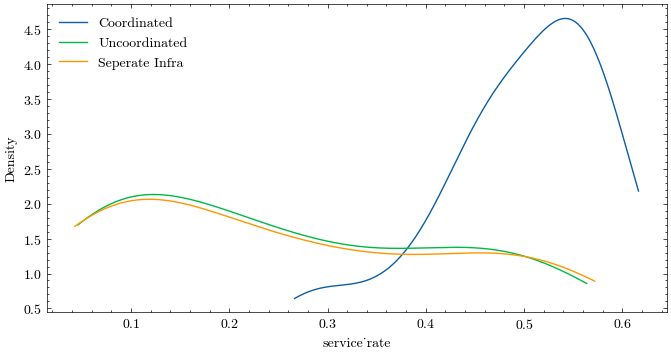

In [73]:
fig, ax = plt.subplots(1,1, figsize=(8,4))

sns.kdeplot(data = service_rate_coordinated, x='service_rate', label='Coordinated', cut=0, ax=ax)
sns.kdeplot(data = service_rate_uncoordinated, x='service_rate', label='Uncoordinated', cut=0, ax=ax)
sns.kdeplot(data = service_rate_seperate, x='service_rate', label='Seperate Infra', cut=0, ax=ax)

ax.legend()

In [74]:
# TODO: waiting time benchmarks

### compare one day with Anthony's results

In [ ]:
benchmark_no_coordination = pd.read_csv("data/output/benchmarks/time_related_kpi_500.csv")

In [ ]:
benchmark_no_coordination

In [ ]:
benchmark_no_coordination.plot(x='timestamp', y='all_vehicles_avg_SOC', figsize=(10, 4))

In [ ]:
benchmark_no_coordination['charging_utilization'] = benchmark_no_coordination['all_stations_utilization_rate'].apply(lambda x: np.mean(eval(x)))

In [ ]:
benchmark_no_coordination.plot(x='timestamp', y='charging_utilization', figsize=(10, 4))

In [ ]:
# compare to our scenario
benchmark_no_coordination['time'] = pd.to_datetime(benchmark_no_coordination['timestamp'].apply(SimulationTimeConverter.as_time), format="%H:%M:%S")

fig, ax = plt.subplots(1,2, figsize=(12,4))

sns.lineplot(data=charging_station_tracking_coordinated, x='time', y='system_wide_utilization', ax=ax[0])
ax[0].set_ylabel('Charging Infrastructure Utilization')
ax[0].set_title('a) Shared Infrastructure, Coordination Mechanism')

sns.lineplot(data=benchmark_no_coordination, x='timestamp', y='charging_utilization', ax=ax[1])
ax[1].set_ylabel('Charging Infrastructure Utilization')
ax[1].set_title('b) Shared Infrastructure, Queueing')

for a in ax:
    a.set_ylim(0, 1.0)
    a.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=SIM_DAYS +  1))
    a.xaxis.set_major_formatter(mdates.DateFormatter('%a %H:%M'))

NameError: name 'benchmark_no_coordination' is not defined

In [ ]:
# compare to our scenario
fig, ax = plt.subplots(1,2, figsize=(10,4))

sns.lineplot(data=vehicle_tracking, x='time', y='fleet_average_SOC', hue='_fleet', ax = ax[0])
ax[0].set_ylabel('Fleet Average SOC (in %)')
ax[0].set_title('a) Shared Infrastructure, Coordination Mechanism')

sns.lineplot(data=benchmark_no_coordination, x='timestamp', y='all_vehicles_avg_SOC', ax=ax[1])
ax[1].set_ylabel('Fleet Average SOC (in %)')
ax[1].set_title('b) Shared Infrastructure, Queueing')

for a in ax:
    a.set_ylim(0, 100)
    a.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=12))
    a.xaxis.set_major_formatter(mdates.DateFormatter('%H'))

NameError: name 'vehicle_tracking' is not defined

Error in callback <function _draw_all_if_interactive at 0x11a52d670> (for post_execute), with arguments args (),kwargs {}:


RuntimeError: Failed to process string with tex because latex could not be found

RuntimeError: Failed to process string with tex because latex could not be found

<Figure size 1000x400 with 2 Axes>

In [ ]:
benchmark_no_coordination['vehicles_avg_waiting_times'] = benchmark_no_coordination['all_vehicles_waiting_times'].apply(lambda x: np.mean([y[0] for y in eval(x) if len(y) > 0]))

In [ ]:
# compare to our scenario
fig, ax = plt.subplots(1,2, figsize=(10,4))

sns.lineplot(data=hourly_tasks, x='timestamp', y='avg_waiting_time_fleet_0', label='fleet_0', ax=ax[0])
sns.lineplot(data=hourly_tasks, x='timestamp', y='avg_waiting_time_fleet_1', label='fleet_1', ax=ax[0])

sns.lineplot(data=benchmark_no_coordination, x='timestamp', y='vehicles_avg_waiting_times', ax=ax[1])


NameError: name 'hourly_tasks' is not defined

Error in callback <function _draw_all_if_interactive at 0x11a52d670> (for post_execute), with arguments args (),kwargs {}:


RuntimeError: Failed to process string with tex because latex could not be found

RuntimeError: Failed to process string with tex because latex could not be found

<Figure size 1000x400 with 2 Axes>

In [ ]:
metrics_no_coordination = pd.read_csv("data/output/benchmarks/end_of_sim_kpi_500.csv")

In [ ]:
metrics_no_coordination

In [ ]:
display(transactions_fleet_0.value_counts('state'))
display(transactions_fleet_1.value_counts('state'))

In [ ]:
pd.DataFrame([
    {
        'fleet': 0,
        'service_rate_coordination': sum(transactions_fleet_0['state'] == 'Fulfilled') / transactions_fleet_0.shape[0],
        'service_rate_queuing': metrics_no_coordination.at[0, 'fleet_0_total_fulfilled_trips_ride_hailing'] / (metrics_no_coordination.at[0, 'fleet_0_total_fulfilled_trips_ride_hailing'] + metrics_no_coordination.at[0, 'fleet_0_total_missed_trips_ride_hailing'])
    },
    {
        'fleet': 1,
        'service_rate_coordination': sum(transactions_fleet_1['state'] == 'Fulfilled') / transactions_fleet_1.shape[0],
        'service_rate_queuing': metrics_no_coordination.at[0, 'fleet_1_total_fulfilled_trips_ride_hailing'] / (metrics_no_coordination.at[0, 'fleet_1_total_fulfilled_trips_ride_hailing'] + metrics_no_coordination.at[0, 'fleet_1_total_missed_trips_ride_hailing'])
    }    
])

### other stuff

In [ ]:
sns.scatterplot(transactions_fleet_0, x='waiting_time', y='pick_up_time', alpha=.1)

In [ ]:
transactions_fleet_0['pick_up_time'].describe()